#### 이진 분류

In [2]:
import torch
import matplotlib.pyplot as plt

step1. 데이터 생성

In [7]:
N=20

random0=torch.randn(int(N/2), 1)
random5=torch.randn(int(N/2), 1)+5

# data
class1_data=torch.hstack([random0, random5])        # 10행 2열
class2_data=torch.hstack([random5, random0])

# label
class1_label=torch.ones(int(N/2), 1)                # 10행 1열
class2_label=torch.zeros(int(N/2), 1)

x=torch.vstack([class1_data, class2_data])          # 20행 2열
y=torch.vstack([class1_label, class2_label])        # 20행 1열
print(x)
print(y)

tensor([[ 0.2009,  4.8318],
        [-0.3131,  5.7552],
        [-0.1817,  5.8270],
        [ 1.6343,  4.1734],
        [-0.9594,  4.5700],
        [-0.5590,  5.0742],
        [ 0.1777,  3.1787],
        [-1.7236,  6.7350],
        [ 0.3551,  3.7207],
        [ 1.8370,  6.1730],
        [ 4.8318,  0.2009],
        [ 5.7552, -0.3131],
        [ 5.8270, -0.1817],
        [ 4.1734,  1.6343],
        [ 4.5700, -0.9594],
        [ 5.0742, -0.5590],
        [ 3.1787,  0.1777],
        [ 6.7350, -1.7236],
        [ 3.7207,  0.3551],
        [ 6.1730,  1.8370]])
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])


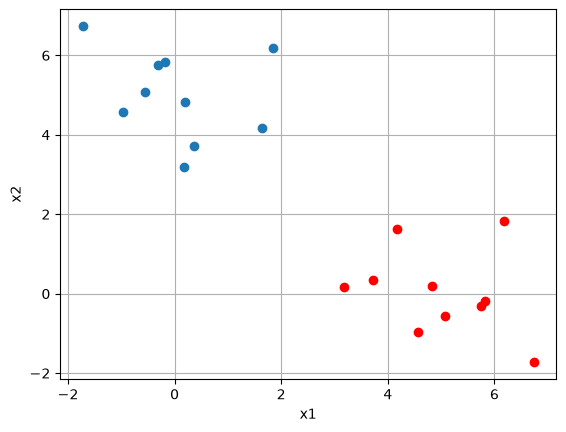

In [12]:
plt.plot(class1_data[:, 0], class1_data[:, 1], 'o')
plt.plot(class2_data[:, 0], class2_data[:, 1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()

#### Step2. 모델 만들기

In [13]:
from torch import nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear=nn.Sequential(nn.Linear(2, 100), nn.Sigmoid(), nn.Linear(100, 1), nn.Sigmoid())
    def forward(self, x):
        x=self.linear(x)
        return x

In [16]:
model=MLP()
print(model)

b=model(torch.randn(5, 2))
print(b.shape)
print(b)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=2, out_features=100, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=100, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
torch.Size([5, 1])
tensor([[0.4772],
        [0.5192],
        [0.4865],
        [0.5119],
        [0.4994]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습시키기

In [ ]:
from torch import optim

LR=100
EPOCH=100

optimizer=optim.SGD(model.parameters(), lr=LR)
criterion=nn.BCELoss()

loss_history=[]

model.train()           # train mode로 전환
for ep in range(EPOCH):
    # 예측값
    y_hat=model(x)

    # loss구하기
    loss=criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # print
    loss_history+=[loss_history]
    print(f'Epoch: {ep+1}, train loss: {loss.item():.4f}')
    print('-'*20)

Epoch: 1, train loss: 0.7705
--------------------
Epoch: 2, train loss: 0.6199
--------------------
Epoch: 3, train loss: 0.5125
--------------------
Epoch: 4, train loss: 0.4325
--------------------
Epoch: 5, train loss: 0.3718
--------------------
Epoch: 6, train loss: 0.3248
--------------------
Epoch: 7, train loss: 0.2876
--------------------
Epoch: 8, train loss: 0.2577
--------------------
Epoch: 9, train loss: 0.2331
--------------------
Epoch: 10, train loss: 0.2126
--------------------
Epoch: 11, train loss: 0.1953
--------------------
Epoch: 12, train loss: 0.1805
--------------------
Epoch: 13, train loss: 0.1678
--------------------
Epoch: 14, train loss: 0.1567
--------------------
Epoch: 15, train loss: 0.1469
--------------------
Epoch: 16, train loss: 0.1383
--------------------
Epoch: 17, train loss: 0.1306
--------------------
Epoch: 18, train loss: 0.1238
--------------------
Epoch: 19, train loss: 0.1175
--------------------
Epoch: 20, train loss: 0.1119
----------